# Taghastinos di 41

# First things first : importing libraries 

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
#import seaborn as sns
from sklearn.impute import SimpleImputer

# Inspect Data Structure and Check Missing Values

In [17]:


df = pd.read_csv("bird.csv")

print("="*50)
print("DATASET OVERVIEW")
print("="*50)

print("\nShape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nMissing Percentage:")
print((df.isnull().sum()/len(df)*100).round(2))

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nSummary Statistics:")
print(df.describe(include='all'))
# Visualize missing values
plt.figure(figsize=(12, 6))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title("Missing Values Heatmap")
plt.show()
# Missing value counts Bar Chart 
missing_counts = df.isnull().sum()
missing_counts[missing_counts > 0].sort_values().plot(
    kind='barh',
    figsize=(10,6),
    color='red'
)

plt.title("Missing Values per Column")
plt.xlabel("Number of Missing Values")
plt.ylabel("Columns")
plt.show()
# Missing Percentage Visualization


DATASET OVERVIEW

Shape: (420, 12)

Column Names:
['id', 'huml', 'humw', 'ulnal', 'ulnaw', 'feml', 'femw', 'tibl', 'tibw', 'tarl', 'tarw', 'type']

Data Types:
id         int64
huml     float64
humw     float64
ulnal    float64
ulnaw    float64
feml     float64
femw     float64
tibl     float64
tibw     float64
tarl     float64
tarw     float64
type         str
dtype: object

Missing Values:
id       0
huml     1
humw     1
ulnal    3
ulnaw    2
feml     2
femw     1
tibl     2
tibw     1
tarl     1
tarw     1
type     0
dtype: int64

Missing Percentage:
id       0.00
huml     0.24
humw     0.24
ulnal    0.71
ulnaw    0.48
feml     0.48
femw     0.24
tibl     0.48
tibw     0.24
tarl     0.24
tarw     0.24
type     0.00
dtype: float64

Duplicate Rows:
0

Summary Statistics:
                id        huml        humw       ulnal       ulnaw  \
count   420.000000  419.000000  419.000000  417.000000  418.000000   
unique         NaN         NaN         NaN         NaN         NaN   
top   

NameError: name 'sns' is not defined

<Figure size 1200x600 with 0 Axes>

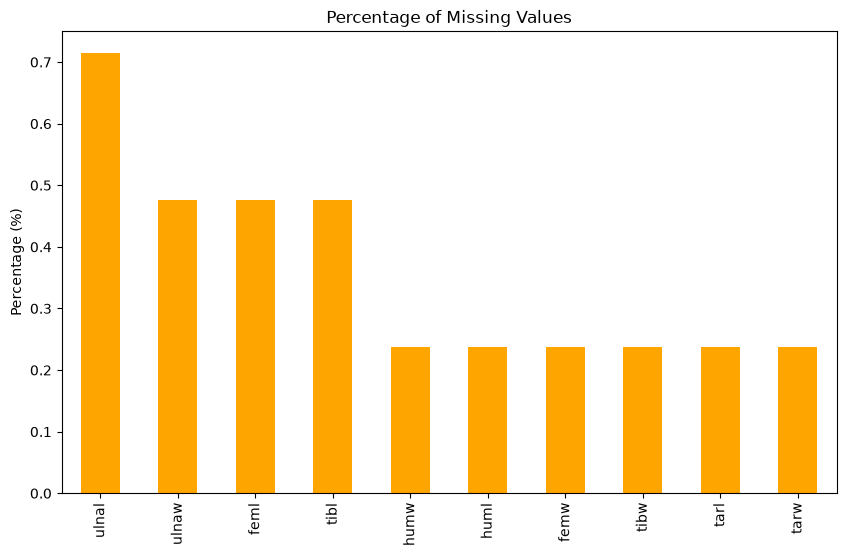

In [18]:
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_percent[missing_percent > 0].sort_values(
    ascending=False
).plot(
    kind='bar',
    figsize=(10,6),
    color='orange'
)

plt.title("Percentage of Missing Values")
plt.ylabel("Percentage (%)")
plt.show()

In [19]:
import missingno as msno
import matplotlib.pyplot as plt

ModuleNotFoundError: No module named 'missingno'

In [20]:
#Correlation Heatmap of Missingness

In [21]:
msno.heatmap(df)
plt.show()

NameError: name 'msno' is not defined

In [22]:
msno.dendrogram(df)
plt.show()

NameError: name 'msno' is not defined

In [23]:
# Figures for the Assessement 1

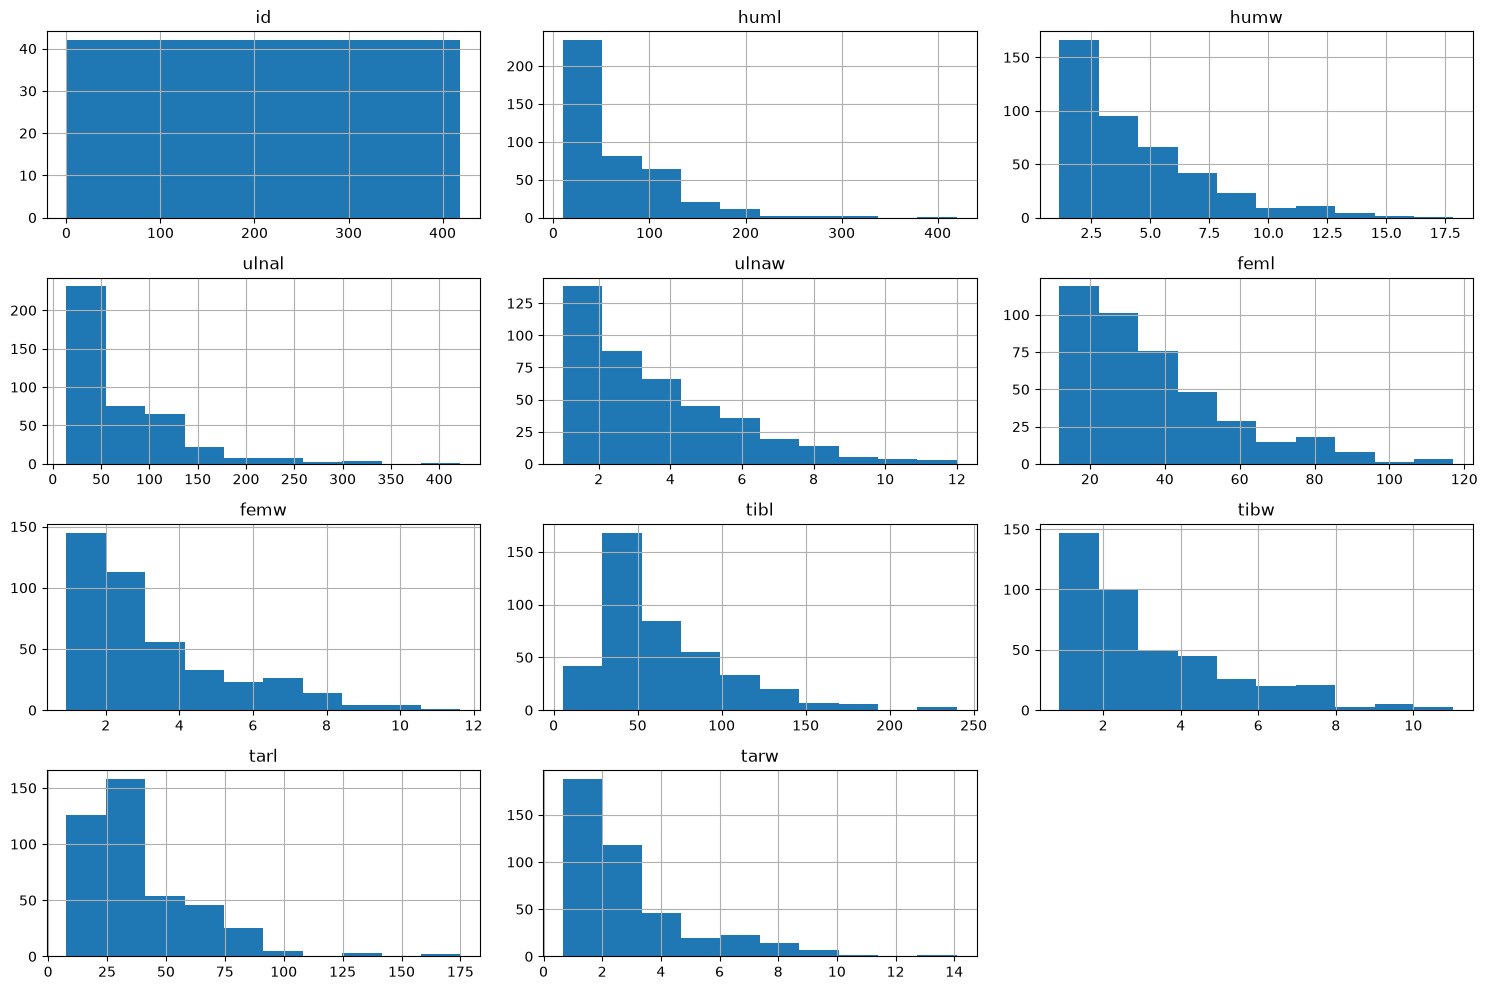

In [24]:
# Distribution Analysis
df.hist(figsize=(15,10))
plt.savefig(
    "figures/class_Distribution_Histo.png",
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)
plt.tight_layout()
plt.show()

In [25]:
# Correlation Analysis
import seaborn as sns

corr = df.drop(columns=['id']).corr(numeric_only=True)

plt.savefig(
    "figures/class_correlation.png",
    dpi=600,
    bbox_inches='tight',
    facecolor='white'
)
sns.heatmap(corr,
            annot=True,
            cmap='coolwarm')
plt.show()

ModuleNotFoundError: No module named 'seaborn'

In [ ]:
# Classe distrubution 
sns.countplot(data=df, x='type')
plt.show()

In [ ]:
# Class counts
print(df['type'].value_counts())

# Visualization
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='type', order=df['type'].value_counts().index)

plt.title("Class Distribution by Bird Type")
plt.xlabel("Bird Type")
plt.ylabel("Count")
plt.show()

In [ ]:
class_dist = df['type'].value_counts()

plt.figure(figsize=(8,5))
ax = sns.countplot(
    data=df,
    x='type',
    order=class_dist.index
)

total = len(df)

for p in ax.patches:
    percentage = 100 * p.get_height() / total
    ax.annotate(
        f'{percentage:.1f}%',
        (p.get_x() + p.get_width()/2., p.get_height()),
        ha='center',
        va='bottom'
    )

plt.title("Bird Type Distribution (%)")
plt.savefig(
    "figures/class_distribution_barChart.png",
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)
plt.show()

In [ ]:
df['type'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    figsize=(7,7)
)

plt.ylabel("")
plt.title("Distribution of Bird Types")
plt.savefig(
    "figures/class_distribution_Pie.png",
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)
plt.show()

In [26]:
class_counts = df['type'].value_counts()

summary = pd.DataFrame({
    'Count': class_counts,
    'Percentage': round(class_counts / len(df) * 100, 2)
})

print(summary)

      Count  Percentage
type                   
SO      128       30.48
SW      116       27.62
W        65       15.48
R        50       11.90
P        38        9.05
T        23        5.48


In [27]:
print(df['type'].value_counts(normalize=True) * 100)


type
SO    30.476190
SW    27.619048
W     15.476190
R     11.904762
P      9.047619
T      5.476190
Name: proportion, dtype: float64


# Exploratory Data Analysis
Prior to preprocessing, an exploratory analysis was performed to understand the 
characteristics of the dataset and identify potential data quality issues.
The following analyses were conducted:

# 1- Dataset Structure Analysis
The dimensions of the dataset, data types, and feature descriptions were examined using:

In [28]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 420 entries, 0 to 419
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   id      420 non-null    int64  
 1   huml    419 non-null    float64
 2   humw    419 non-null    float64
 3   ulnal   417 non-null    float64
 4   ulnaw   418 non-null    float64
 5   feml    418 non-null    float64
 6   femw    419 non-null    float64
 7   tibl    418 non-null    float64
 8   tibw    419 non-null    float64
 9   tarl    419 non-null    float64
 10  tarw    419 non-null    float64
 11  type    420 non-null    str    
dtypes: float64(10), int64(1), str(1)
memory usage: 40.2 KB


,id,huml,humw,ulnal,ulnaw,feml,femw,tibl,tibw,tarl,tarw
count,420.000000,419.000000,419.000000,417.000000,418.000000,418.000000,419.000000,418.000000,419.000000,419.000000,419.000000
mean,209.500000,64.650501,4.370573,69.115372,3.597249,36.872416,3.220883,64.662823,3.182339,39.229976,2.930024
std,121.387808,53.834549,2.854617,58.784775,2.186747,19.979082,2.023581,37.838145,2.080827,23.184313,2.185673
min,0.000000,9.850000,1.140000,14.090000,1.000000,11.830000,0.930000,5.500000,0.870000,7.770000,0.660000
25%,104.750000,25.170000,2.190000,28.050000,1.870000,21.297500,1.715000,36.417500,1.565000,23.035000,1.425000
50%,209.500000,44.180000,3.500000,43.710000,2.945000,31.130000,2.520000,52.120000,2.490000,31.740000,2.230000
75%,314.250000,90.310000,5.810000,97.520000,4.770000,47.120000,4.135000,82.870000,4.255000,50.250000,3.500000
max,419.000000,420.000000,17.840000,422.000000,12.000000,117.070000,11.640000,240.000000,11.030000,175.000000,14.090000


# Missing Value Analysis
- Missing values were identified and quantified for each feature.
- A missing-value heatmap was generated to visualize the distribution of incomplete observations.

In [29]:
df.isnull().sum()
sns.heatmap(df.isnull())

NameError: name 'sns' is not defined

# Class Distribution Analysis
The distribution of bird categories was analyzed to determine whether the dataset suffers from class imbalance.

In [ ]:
sns.countplot(x='type', data=df)
plt.savefig(
    "figures/class_distribution_bar_chart.png",
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

# Outlier Detection
Boxplots were used to identify extreme measurements that may affect model performance.

In [ ]:
# 1. Set the academic style rules
sns.set_theme(style="ticks", context="paper", font_scale=1.1)

# 2. Reshape your data from wide to long format
cols_to_plot = ['huml', 'humw', 'ulnal', 'ulnaw', 'feml', 'femw', 'tibl', 'tibw', 'tarl', 'tarw']
		
df_long = df.melt(id_vars=['type'], value_vars=cols_to_plot, 
                  var_name='Measurement', value_name='Value')

# 3. Create the multi-panel plot
# Swapping x and y sets the plot horizontally
g = sns.catplot(
    data=df_long, 
    y='type',                # Type categories now sit clearly on the Y-axis
    x='Value',                # Measurement values sit on the X-axis
    col='Measurement', 
    kind='box', 
    col_wrap=4,
    palette='Set2',          # Clean academic color palette
    linewidth=1.2,           
    fliersize=4,             
    sharex=False,            # CRITICAL: Each skeletal metric keeps its own scale on X
    height=3.5,              
    aspect=0.9
)

# 4. Rigorous academic adjustments (Spines, Labels, Aesthetics)
g.set_titles(row_template='{row_name}', col_template='{col_name}')
g.set_axis_labels("Value (mm)", "") # Clear units on X, clean Y-axis boundary

# Clean up layout, drop extra outer borders
sns.despine(trim=True) 
plt.subplots_adjust(top=0.9) 

# Save a lossless high-resolution version for submission
# plt.savefig('skeletal_measurements_horizontal.pdf', bbox_inches='tight')

plt.show()

# Correlation Analysis
A correlation matrix was generated to examine relationships between skeletal measurements.

In [ ]:
sns.heatmap(df.corr(==True),
            annot=True,
            cmap='coolwarm')

# Data Preprocessing

Data preprocessing was performed to improve data quality and prepare the dataset for machine learning algorithms.

Removal of Irrelevant Features

The identifier (id) column was removed because it contains no predictive information.

In [ ]:
df.drop('id', axis=1, inplace=True)

# Handling Missing Values

Missing numerical values were replaced using median imputation. 
Median imputation was selected because it is robust to outliers and preserves the central tendency of each feature.

In [ ]:
columns_to_impute = ['huml', 'ulnal', 'ulnaw', 'feml', 'femw', 'tibl', 'tibw', 'tarl']
imputer = SimpleImputer(strategy='median')
# This will fill missing values across all specified columns using their respective medians
df[columns_to_impute] = imputer.fit_transform(df[columns_to_impute])

In [ ]:
df.drop_duplicates(inplace=True)

# Duplicate Record Removal
Duplicate observations were identified and removed.

In [ ]:
df.drop_duplicates(inplace=True)

# Label Encoding

The target variable was transformed into numerical labels for model compatibility.

In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['type'] = le.fit_transform(df['type'])

# Feature Standardization
The predictor variables were standardized using z-score normalization to ensure comparable feature scales.

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = scaler.fit_transform(X)